## Ahn–Farmer Replication

### 1. Data & Measurement

Available sheets: ['NGDP', 'PGDP', 'CPROF', 'UNEMP', 'EMP', 'INDPROD', 'HOUSING', 'TBILL', 'BOND', 'BAABOND', 'TBOND', 'RGDP', 'RCONSUM', 'RNRESIN', 'RRESINV', 'RFEDGOV', 'RSLGOV', 'RCBI', 'REXPORT', 'CPI5YR', 'PCE5YR', 'CPI10', 'PCE10', 'RGDP10', 'PROD10', 'STOCK10', 'BOND10', 'BILL10', 'PRGDP', 'PRPGDP', 'PRUNEMP', 'PRCCPI', 'PRCPCE', 'RECESS', 'CPI', 'CORECPI', 'PCE', 'COREPCE', 'UBAR', 'SPR_TBOND_TBILL', 'SPR_BAA_AAA', 'SPR_BAA_TBOND', 'SPR_AAA_TBOND', 'CPIF5', 'PCEF5', 'RR1_TBILL_PGDP', 'RR2_TBILL_PGDP', 'RR3_TBILL_PGDP', 'RR1_TBILL_CPI', 'RR2_TBILL_CPI', 'RR3_TBILL_CPI', 'RR1_TBILL_CCPI', 'RR2_TBILL_CCPI', 'RR3_TBILL_CCPI', 'RR1_TBILL_PCE', 'RR2_TBILL_PCE', 'RR3_TBILL_PCE', 'RR1_TBILL_CPCE', 'RR2_TBILL_CPCE', 'RR3_TBILL_CPCE']
Invalid rows excluded: 3773

SPF SAMPLE
Original forecasters: 192
Retained forecasters: 97
Survey quarters: 134
Observations: 4446
Sample: 1991Q4 2025Q1
CPI3      4446
CPI6      4446
CPI5YR    2521
CPI10     3854
dtype: int64


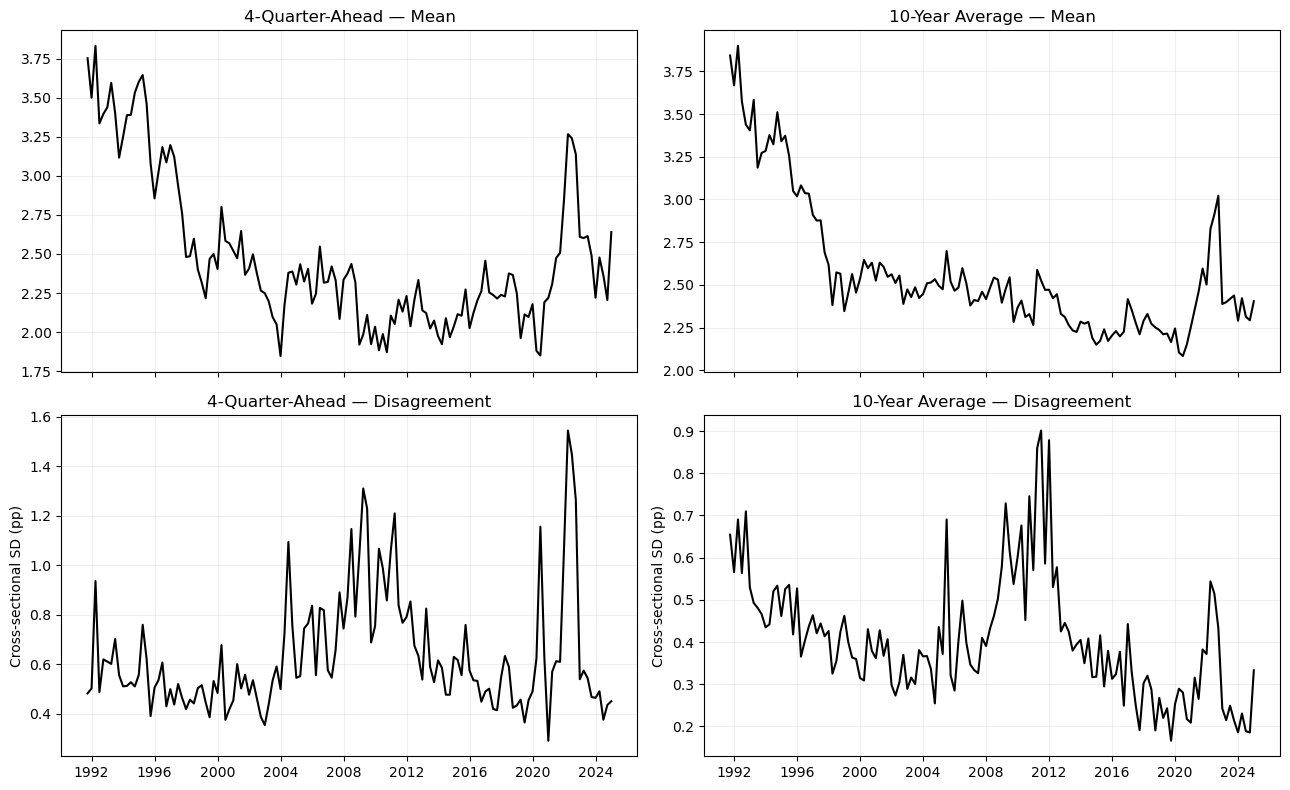

Maximum disagreement:
4Q: 1.5448506132114475
10Y: 0.9010681031633854

MEASUREMENT EQUATIONS
Observations: 27499
Forecasters: 97
question
CPI10     1948
CPI3      4446
CPI4      4446
CPI5      4446
CPI5YR    1262
CPI6      4446
CPIB      4231
CPIC      2274
Name: count, dtype: int64
          h1      h2          a       
         min max min max    min    max
question                              
CPI10      0   0  38  39  0.153  0.157
CPI3       0   0   1   1  0.921  0.921
CPI4       1   1   2   2  0.779  0.779
CPI5       2   2   3   3  0.659  0.659
CPI5YR     0   0  18  19  0.301  0.316
CPI6       3   3   4   4  0.557  0.557
CPIB       0   3   4   7  0.441  0.729
CPIC       4   7   8  11  0.226  0.373

Macro alignment:
Survey quarters: 134
Macro matches: 134
D_4q         134
D_10y        134
inflation    134
UNRATE       134
FEDFUNDS     134
dtype: int64


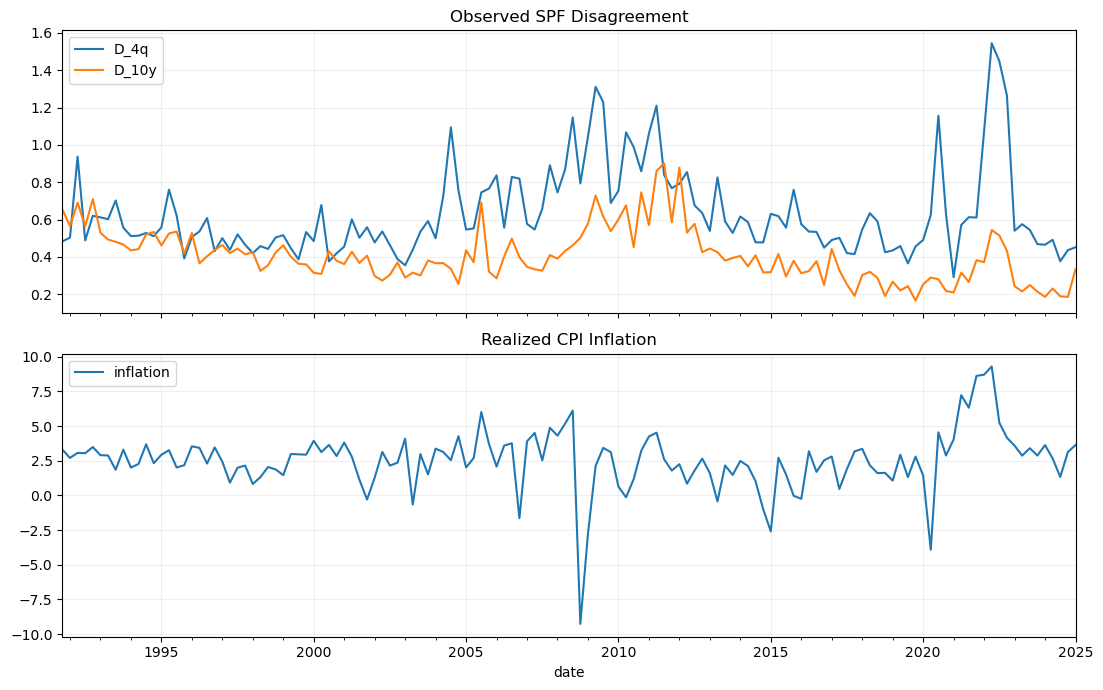


CELL 1 COMPLETED
Outputs: spf, sample, obs
No files saved.


In [11]:

# ============================================================
# CELL 1 — AHN–FARMER REPLICATION
# DATA LOADING / SAMPLE / MEASUREMENT EQUATIONS
# Original specification
# ============================================================

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from io import BytesIO
from lxml import etree
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path(r"C:\Users\gayeon\Dropbox\key_data")
SPF = ROOT / "SPFmicrodata.xlsx"
MACRO = ROOT / "macro" / "processed" / "macro_quarterly.csv"

assert SPF.exists(), f"File not found: {SPF}"

ns = "{http://schemas.openxmlformats.org/spreadsheetml/2006/main}"

# ------------------------------------------------------------
# 1. Read SPF directly from Excel XML
#    Bypasses openpyxl date metadata error
# ------------------------------------------------------------

with ZipFile(SPF) as z:
    shared_root = etree.fromstring(
        z.read("xl/sharedStrings.xml")
    )
    shared = [
        "".join(t.text or "" for t in si.iter(ns + "t"))
        for si in shared_root
    ]

    workbook = etree.fromstring(
        z.read("xl/workbook.xml")
    )
    sheets = [
        s.get("name")
        for s in workbook.iter(ns + "sheet")
    ]

print("Available sheets:", sheets)

def read_sheet(name):
    sheet_number = sheets.index(name) + 1

    with ZipFile(SPF) as z:
        with z.open(
            f"xl/worksheets/sheet{sheet_number}.xml"
        ) as f:
            rows = []

            for _, element in etree.iterparse(
                f, events=("end",), tag=ns + "row"
            ):
                cells = {}

                for cell in element.findall(ns + "c"):
                    ref = cell.get("r")
                    col = "".join(
                        c for c in ref if c.isalpha()
                    )

                    value_node = cell.find(ns + "v")
                    value = (
                        value_node.text
                        if value_node is not None else None
                    )

                    if (
                        cell.get("t") == "s"
                        and value is not None
                    ):
                        value = shared[int(value)]

                    cells[col] = value

                rows.append(cells)
                element.clear()

    headers = rows[0]

    df = pd.DataFrame([
        {
            headers[col]: value
            for col, value in row.items()
            if col in headers
        }
        for row in rows[1:]
    ])

    df.columns = (
        df.columns.str.strip().str.upper()
    )

    df = df.replace({
        "#N/A": np.nan,
        "": np.nan
    })

    for col in df.columns:
        if col != "INDUSTRY":
            df[col] = pd.to_numeric(
                df[col], errors="coerce"
            )

    return df

# ------------------------------------------------------------
# 2. Load individual forecasts
# ------------------------------------------------------------

cpi = read_sheet("CPI")
cpi5 = read_sheet("CPI5YR")
cpi10 = read_sheet("CPI10")
cpif5 = read_sheet("CPIF5")

keys = ["YEAR", "QUARTER", "ID"]

spf = (
    cpi.merge(
        cpi5[keys + ["CPI5YR"]],
        on=keys, how="left",
        validate="one_to_one"
    )
    .merge(
        cpi10[keys + ["CPI10"]],
        on=keys, how="left",
        validate="one_to_one"
    )
)

spf = spf.merge(
    cpif5[keys + ["CPIF5"]],
    on=keys, how="left",
    validate="one_to_one"
)

# ------------------------------------------------------------
# 3. Sample selection
# ------------------------------------------------------------

valid = (
    spf.YEAR.between(1991, 2025)
    & spf.QUARTER.isin([1, 2, 3, 4])
    & spf.ID.notna()
)

print("Invalid rows excluded:", (~valid).sum())

spf = spf.loc[valid].copy()

spf["period"] = pd.PeriodIndex(
    spf.YEAR.astype(int).astype(str)
    + "Q"
    + spf.QUARTER.astype(int).astype(str),
    freq="Q"
)

spf = spf.loc[
    spf.period.between(
        pd.Period("1991Q4"),
        pd.Period("2025Q1")
    )
].copy()

spf["date"] = spf.period.dt.to_timestamp()

short = [
    "CPI2", "CPI3", "CPI4",
    "CPI5", "CPI6"
]

spf["complete_short"] = (
    spf[short].notna().all(axis=1)
)

participation = (
    spf.loc[spf.complete_short]
    .groupby("ID")
    .period.nunique()
)

valid_ids = participation[
    participation >= 12
].index

sample = spf.loc[
    spf.complete_short
    & spf.ID.isin(valid_ids)
].copy()

assert not sample.duplicated(keys).any()

print("\n" + "="*60)
print("SPF SAMPLE")
print("="*60)

print("Original forecasters:", spf.ID.nunique())
print("Retained forecasters:", sample.ID.nunique())
print("Survey quarters:", sample.period.nunique())
print("Observations:", len(sample))
print("Sample:", sample.period.min(), sample.period.max())

print(
    sample[
        ["CPI3", "CPI6", "CPI5YR", "CPI10"]
    ].count()
)

# ------------------------------------------------------------
# 4. Figure A1 — Raw forecast diagnostics
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 2, figsize=(13, 8), sharex=True
)

for j, (col, title) in enumerate([
    ("CPI6", "4-Quarter-Ahead"),
    ("CPI10", "10-Year Average")
]):
    g = sample.groupby("date")[col]
    mean = g.mean()
    sd = g.std()

    sd[g.count() < 10] = np.nan

    axes[0, j].plot(mean.index, mean, color="black")
    axes[0, j].set_title(title + " — Mean")

    axes[1, j].plot(sd.index, sd, color="black")
    axes[1, j].set_title(title + " — Disagreement")
    axes[1, j].set_ylabel("Cross-sectional SD (pp)")

for ax in axes.flat:
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

print("Maximum disagreement:")
print("4Q:", sample.groupby("date").CPI6.std().max())
print("10Y:", sample.groupby("date").CPI10.std().max())

# ------------------------------------------------------------
# 5. Original measurement equations
# ------------------------------------------------------------

lam = 0.1673

def loading(h1, h2):
    return (
        np.exp(-lam*h1)
        - np.exp(-lam*h2)
    ) / (lam*(h2-h1))

records = []

for r in sample.itertuples(index=False):
    q = int(r.QUARTER)

    windows = {
        "CPI3": (0, 1),
        "CPI4": (1, 2),
        "CPI5": (2, 3),
        "CPI6": (3, 4),
        "CPIB": (4-q, 8-q),
        "CPIC": (8-q, 12-q)
    }

    values = {
        name: getattr(r, name, np.nan)
        for name in windows
    }

    # Original Q1/Q2 adjustment
    realized = [r.CPI2, r.CPI1]

    if q <= 2 and all(
        pd.notna(x) for x in realized[:q]
    ):
        past = sum(realized[:q])

        if pd.notna(r.CPI5YR):
            windows["CPI5YR"] = (0, 20-q)
            values["CPI5YR"] = (
                20*r.CPI5YR-past
            ) / (20-q)

        if pd.notna(r.CPI10):
            windows["CPI10"] = (0, 40-q)
            values["CPI10"] = (
                40*r.CPI10-past
            ) / (40-q)

    for name, (h1, h2) in windows.items():
        value = values.get(name, np.nan)

        if pd.notna(value):
            records.append({
                "date": r.date,
                "ID": r.ID,
                "question": name,
                "y": float(value),
                "h1": h1,
                "h2": h2,
                "a": loading(h1, h2)
            })

obs = pd.DataFrame(records)

assert not obs.duplicated(
    ["date", "ID", "question"]
).any()

print("\n" + "="*60)
print("MEASUREMENT EQUATIONS")
print("="*60)

print("Observations:", len(obs))
print("Forecasters:", obs.ID.nunique())
print(obs.question.value_counts().sort_index())

print(
    obs.groupby("question")[
        ["h1", "h2", "a"]
    ].agg(["min", "max"]).round(3)
)

# ------------------------------------------------------------
# 6. Macro alignment
# ------------------------------------------------------------

if MACRO.exists():
    macro = pd.read_csv(
        MACRO,
        parse_dates=["date"]
    ).set_index("date").sort_index()

    macro.index = (
        macro.index.to_period("Q").to_timestamp()
    )

    assert macro.index.is_unique

    inflation_col = next(
        (
            c for c in [
                "inflation_cpi_q_ann",
                "CPIAUCSL_ann_qoq",
                "CPIAUCSL"
            ]
            if c in macro.columns
        ),
        None
    )

    assert inflation_col is not None

    macro["inflation"] = (
        400*np.log(macro["CPIAUCSL"]).diff()
        if inflation_col == "CPIAUCSL"
        else macro[inflation_col]
    )

    survey_dates = pd.Index(
        sorted(sample.date.unique()),
        name="date"
    )

    macro_aligned = macro.reindex(survey_dates)

    print("\nMacro alignment:")
    print("Survey quarters:", len(survey_dates))
    print(
        "Macro matches:",
        macro_aligned.inflation.notna().sum()
    )

    D = sample.groupby("date").agg(
        D_4q=("CPI6", "std"),
        D_10y=("CPI10", "std")
    )

    analysis = D.join(
        macro_aligned[
            ["inflation", "UNRATE", "FEDFUNDS"]
        ],
        how="left"
    )

    print(analysis.count())

    fig, ax = plt.subplots(
        2, 1, figsize=(11, 7), sharex=True
    )

    analysis[["D_4q", "D_10y"]].plot(ax=ax[0])
    ax[0].set_title("Observed SPF Disagreement")

    analysis[["inflation"]].plot(ax=ax[1])
    ax[1].set_title("Realized CPI Inflation")

    for a_plot in ax:
        a_plot.grid(alpha=0.2)

    plt.tight_layout()
    plt.show()
else:
    print("\nMacro file not found; SPF obs is still ready.")

print("\nCELL 1 COMPLETED")
print("Outputs: spf, sample, obs")
print("No files saved.")


### 2. Joint Bayesian State-Space Estimation

State-space structure

$$
\begin{aligned}
y_{itj}
={}&\alpha_i^L-a_j\alpha_i^S
+\beta_i^LC_t^L-a_j\beta_i^SC_t^S\\
&+E_{it}^L-a_jE_{it}^S+\varepsilon_{itj},
\end{aligned}
$$

$$
\begin{pmatrix}C_t^L\\C_t^S\end{pmatrix} =
\begin{pmatrix}1&0\\0&\rho_C\end{pmatrix}
\begin{pmatrix}C_{t-1}^L\\C_{t-1}^S\end{pmatrix}
+\eta_t,
\quad \eta_t\sim N(0,I_2),
$$

$$
\begin{pmatrix}E_{it}^L\\E_{it}^S\end{pmatrix}=
\begin{pmatrix}\rho_L&0\\0&\rho_S\end{pmatrix}
\begin{pmatrix}E_{i,t-1}^L\\E_{i,t-1}^S\end{pmatrix}
+\nu_{it}.
$$

개별 상태의 innovation covariance는 $Q_E=\operatorname{diag}(q_L,q_S)$.

추정 알고리즘은 다음 conditional posterior들을 순차적으로 샘플링함.
$$
\begin{aligned}
\Theta_i&\mid C,E,\rho,q,\lambda,Y,\\
(\rho,q)&\mid C,E,\Theta,\lambda,Y,\\
\sigma_{\varepsilon,j}^2&\mid C,E,\Theta,\lambda,Y,\\
\lambda&\mid C,E,\Theta,\sigma_\varepsilon^2,Y,\\
C_{1:T}&\mid E,\Theta,\rho,q,\lambda,Y,\\
E_{i,1:T}&\mid C,\Theta,\rho,q,\lambda,Y.
\end{aligned}
$$

Forecasters: 97
Quarters: 134
Forecast observations: 27499
Measurement equations: 16
Unobserved categories: [14, 15, 18, 19]
Iteration 100/1300 | lambda=0.1726 | betaS=0.6310
Iteration 200/1300 | lambda=0.1917 | betaS=0.4710
Iteration 300/1300 | lambda=0.1908 | betaS=0.4932
Iteration 400/1300 | lambda=0.1920 | betaS=0.3858
Iteration 500/1300 | lambda=0.1906 | betaS=0.3501
Iteration 600/1300 | lambda=0.1809 | betaS=0.3737
Iteration 700/1300 | lambda=0.1816 | betaS=0.3983
Iteration 800/1300 | lambda=0.1735 | betaS=0.4116
Iteration 900/1300 | lambda=0.1782 | betaS=0.3930
Iteration 1000/1300 | lambda=0.1676 | betaS=0.4225
Iteration 1100/1300 | lambda=0.1713 | betaS=0.4232
Iteration 1200/1300 | lambda=0.1717 | betaS=0.4165
Iteration 1300/1300 | lambda=0.1745 | betaS=0.4050

POSTERIOR PARAMETER SUMMARY
              Median  CI_lower  CI_upper
alpha_L       2.4963    2.4524    2.5599
alpha_S       0.2416    0.1768    0.3368
beta_L        0.1863    0.1427    0.2252
beta_S        0.4124    0.36

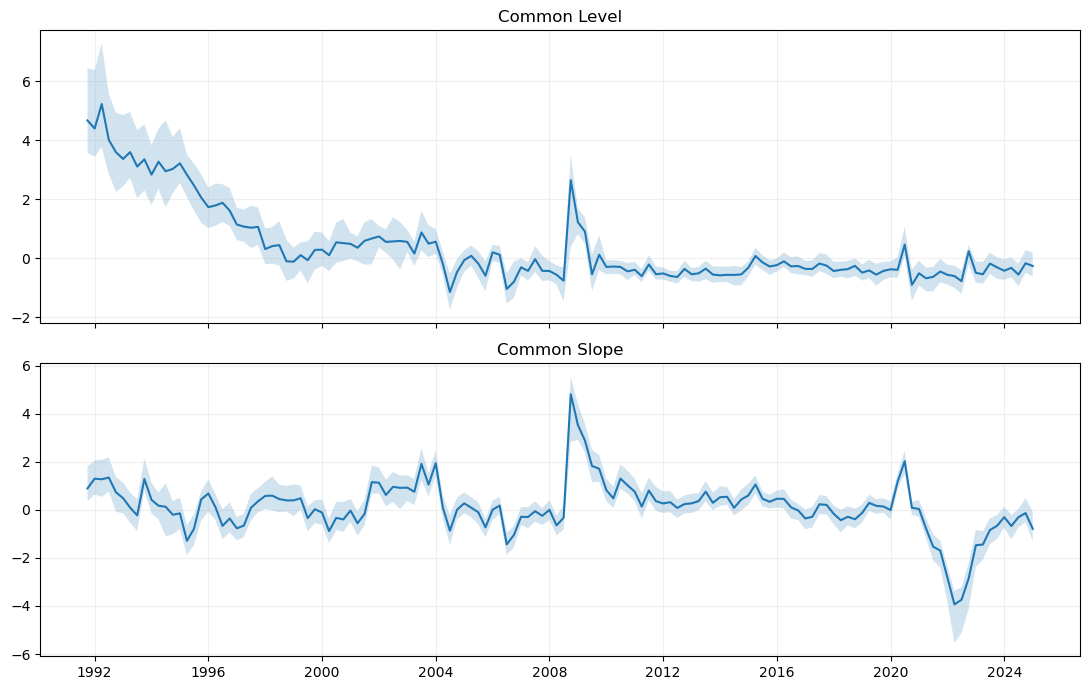

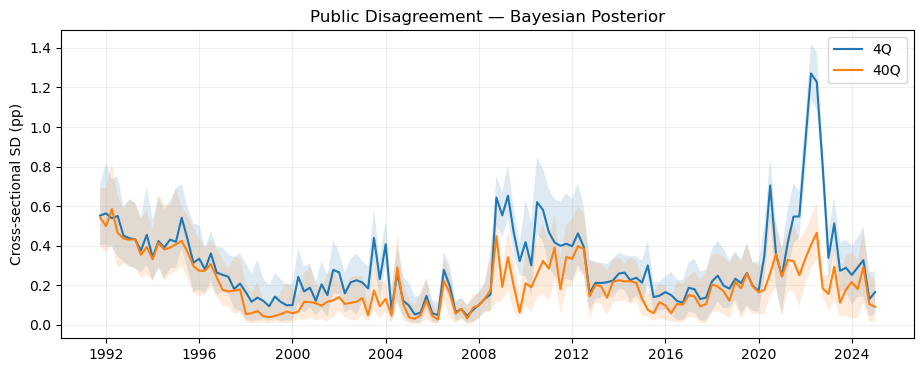

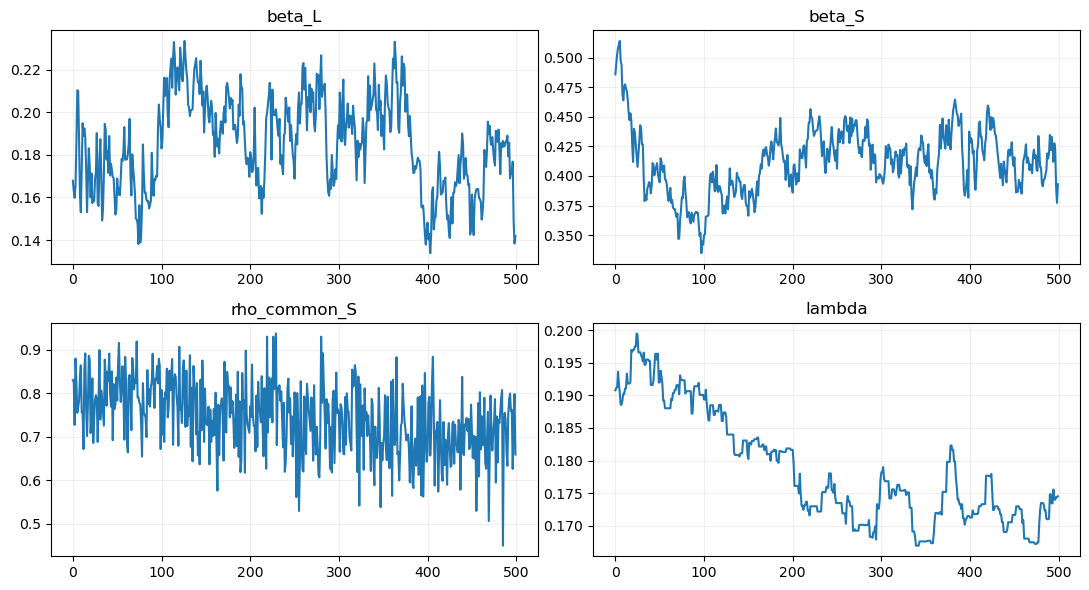


JOINT BAYESIAN SAMPLING COMPLETED
No files saved.


In [12]:

# ============================================================
# CELL 2 — AHN–FARMER JOINT BAYESIAN ESTIMATION
# BLOCKED GIBBS + FFBS + LAMBDA MH
# Requires: obs from Cell 1
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import truncnorm

rng = np.random.default_rng(2026)

# ------------------------------------------------------------
# 1. Build observed panel
# ------------------------------------------------------------

required = ["date", "ID", "question", "y", "h1", "h2"]
assert set(required).issubset(obs.columns)

z = obs[required].dropna().copy()
z["date"] = pd.to_datetime(z["date"])
z = z.sort_values(
    ["date", "ID", "question"]
).reset_index(drop=True)

dates = pd.DatetimeIndex(sorted(z.date.unique()))
ids = np.sort(z.ID.unique())

T, N = len(dates), len(ids)

tmap = {d: t for t, d in enumerate(dates)}
imap = {uid: i for i, uid in enumerate(ids)}

ti = z.date.map(tmap).to_numpy(dtype=int)
ii = z.ID.map(imap).to_numpy(dtype=int)

y = z.y.to_numpy(float)
h1 = z.h1.to_numpy(float)
h2 = z.h2.to_numpy(float)
qtr = z.date.dt.quarter.to_numpy(int)
question = z.question.to_numpy(str)

# 20 survey-quarter-specific question IDs
k = np.full(len(z), -1, dtype=int)

for h in range(1, 5):
    k[question == f"CPI{h+2}"] = h-1

for name, offset in [
    ("CPIB", 4),
    ("CPIC", 8),
    ("CPI5YR", 12),
    ("CPI10", 16)
]:
    mask = question == name
    k[mask] = offset + qtr[mask]-1

assert (k >= 0).all()
assert (h2 > h1).all()
assert not z.duplicated(
    ["date", "ID", "question"]
).any()

by_t = [
    np.flatnonzero(ti == t)
    for t in range(T)
]

by_i = [
    np.flatnonzero(ii == i)
    for i in range(N)
]

by_it = [
    [
        np.flatnonzero((ti == t) & (ii == i))
        for t in range(T)
    ]
    for i in range(N)
]

active = np.zeros((T, N), dtype=bool)
active[ti, ii] = True

print("Forecasters:", N)
print("Quarters:", T)
print("Forecast observations:", len(y))
print("Measurement equations:", np.unique(k).size)
print(
    "Unobserved categories:",
    sorted(set(range(20))-set(k))
)

# ------------------------------------------------------------
# 2. Initial parameters
# ------------------------------------------------------------

def ns_a(lam_value):
    return (
        np.exp(-lam_value*h1)
        - np.exp(-lam_value*h2)
    ) / (lam_value*(h2-h1))

lam = 0.17
a = ns_a(lam)

prior_mu = np.array([2.5, 0.0, 0.2, 0.3])
prior_sd = np.array([3.0, 3.0, 1.0, 1.0])
prior_precision = np.diag(1/prior_sd**2)

theta = np.zeros((N, 4))
theta[:] = prior_mu

for i in range(N):
    ix = by_i[i]
    X = np.column_stack([
        np.ones(len(ix)),
        -a[ix]
    ])

    b = np.linalg.lstsq(
        X, y[ix], rcond=None
    )[0]

    theta[i, :2] = b

C = np.zeros((T, 2))
E = np.zeros((T, N, 2))

rho = np.array([1.0, 0.8, 0.9, 0.7])

qL, qS = 0.12**2, 0.43**2
rvar = np.full(20, 0.30**2)

shape0, scale0 = 3.0, 0.09
common_level_initial_var = 100.0

def fitted():
    return (
        theta[ii, 0]
        - a*theta[ii, 1]
        + theta[ii, 2]*C[ti, 0]
        - a*theta[ii, 3]*C[ti, 1]
        + E[ti, ii, 0]
        - a*E[ti, ii, 1]
    )

def invgamma_draw(shape, scale):
    return 1/rng.gamma(shape, 1/scale)

def draw_rho(
    x, xlag, innovation_var,
    low=-0.99, high=0.99
):
    precision = (
        1/0.5**2
        + np.sum(xlag*xlag)/innovation_var
    )

    variance = 1/precision
    mean = (
        variance*np.sum(xlag*x)/innovation_var
    )

    sd = np.sqrt(variance)

    return truncnorm.rvs(
        (low-mean)/sd,
        (high-mean)/sd,
        loc=mean,
        scale=sd,
        random_state=rng
    )

# ------------------------------------------------------------
# 3. Gaussian conditional FFBS
# ------------------------------------------------------------

def ffbs_block(H_list, residual_list, F, Q, P_init):

    m = 2

    pred_mean = np.zeros((T, m))
    filt_mean = np.zeros((T, m))
    pred_cov = np.zeros((T, m, m))
    filt_cov = np.zeros((T, m, m))

    xp = np.zeros(m)
    Pp = P_init.copy()

    for t in range(T):

        if t > 0:
            xp = F @ filt_mean[t-1]
            Pp = F @ filt_cov[t-1] @ F.T + Q

        pred_mean[t] = xp
        pred_cov[t] = Pp

        H, v, variances = (
            H_list[t],
            residual_list[t][0],
            residual_list[t][1]
        )

        if len(v):
            Pinv = np.linalg.inv(Pp)

            precision = (
                Pinv
                + H.T @ (H/variances[:, None])
            )

            Pf = np.linalg.inv(precision)

            xf = Pf @ (
                Pinv @ xp
                + H.T @ (v/variances)
            )

        else:
            xf, Pf = xp.copy(), Pp.copy()

        filt_mean[t] = xf
        filt_cov[t] = (Pf+Pf.T)/2

    path = np.zeros((T, m))

    path[-1] = rng.multivariate_normal(
        filt_mean[-1],
        filt_cov[-1]
    )

    for t in range(T-2, -1, -1):

        J = (
            filt_cov[t] @ F.T
            @ np.linalg.inv(pred_cov[t+1])
        )

        mean = (
            filt_mean[t]
            + J @ (path[t+1]-pred_mean[t+1])
        )

        cov = (
            filt_cov[t]
            - J @ pred_cov[t+1] @ J.T
        )

        cov = (cov+cov.T)/2

        path[t] = rng.multivariate_normal(
            mean,
            cov + 1e-10*np.eye(2)
        )

    return path

# ------------------------------------------------------------
# 4. Common states
# ------------------------------------------------------------

def draw_common_states():

    base = fitted()

    F = np.diag(rho[:2])
    Q = np.eye(2)

    H_list, R_list = [], []

    for t in range(T):
        ix = by_t[t]

        H = np.column_stack([
            theta[ii[ix], 2],
            -a[ix]*theta[ii[ix], 3]
        ])

        old = H @ C[t]
        resid = y[ix] - base[ix] + old

        H_list.append(H)
        R_list.append((
            resid,
            rvar[k[ix]]
        ))

    init_cov = np.diag([
        common_level_initial_var,
        1/(1-rho[1]**2)
    ])

    return ffbs_block(
        H_list,
        R_list,
        F,
        Q,
        init_cov
    )

# ------------------------------------------------------------
# 5. Idiosyncratic states
# ------------------------------------------------------------

def draw_idiosyncratic_states():

    F = np.diag(rho[2:])
    Q = np.diag([qL, qS])

    init_cov = np.diag([
        qL/(1-rho[2]**2),
        qS/(1-rho[3]**2)
    ])

    for i in range(N):
        base = fitted()

        H_list, R_list = [], []

        for t in range(T):
            ix = by_it[i][t]

            H = np.column_stack([
                np.ones(len(ix)),
                -a[ix]
            ])

            old = H @ E[t, i]
            resid = y[ix] - base[ix] + old

            H_list.append(H)
            R_list.append((
                resid,
                rvar[k[ix]]
            ))

        E[:, i, :] = ffbs_block(
            H_list,
            R_list,
            F,
            Q,
            init_cov
        )

# ------------------------------------------------------------
# 6. Individual coefficients
# ------------------------------------------------------------

def draw_coefficients():

    for i in range(N):
        ix = by_i[i]
        aa = a[ix]
        tt = ti[ix]

        X = np.column_stack([
            np.ones(len(ix)),
            -aa,
            C[tt, 0],
            -aa*C[tt, 1]
        ])

        adjusted = (
            y[ix]
            - E[tt, i, 0]
            + aa*E[tt, i, 1]
        )

        w = 1/rvar[k[ix]]

        precision = (
            prior_precision
            + X.T @ (w[:, None]*X)
        )

        cov = np.linalg.inv(precision)

        mean = cov @ (
            prior_precision @ prior_mu
            + X.T @ (w*adjusted)
        )

        theta[i] = rng.multivariate_normal(
            mean,
            (cov+cov.T)/2
        )

# ------------------------------------------------------------
# 7. AR coefficients and innovation variances
#    Original implementation retained
# ------------------------------------------------------------

def draw_dynamics():

    global rho, qL, qS

    rho[1] = draw_rho(
        C[1:, 1],
        C[:-1, 1],
        1.0
    )

    mask = active[1:]

    for dimension, index, variance in [
        (0, 2, qL),
        (1, 3, qS)
    ]:
        current = E[1:, :, dimension][mask]
        lagged = E[:-1, :, dimension][mask]

        rho[index] = draw_rho(
            current,
            lagged,
            variance
        )

    for dimension in [0, 1]:

        current = E[1:, :, dimension][mask]
        lagged = E[:-1, :, dimension][mask]

        error = (
            current
            - rho[2+dimension]*lagged
        )

        shape = 2.5 + len(error)/2
        scale = (
            0.02 + np.sum(error**2)/2
        )

        value = invgamma_draw(shape, scale)

        if dimension == 0:
            qL = value
        else:
            qS = value

# ------------------------------------------------------------
# 8. Question-specific measurement variances
# ------------------------------------------------------------

def draw_measurement_variances():

    global rvar

    residual = y-fitted()

    for j in range(20):

        ix = np.flatnonzero(k == j)

        if len(ix) == 0:
            continue

        shape = shape0 + len(ix)/2
        scale = (
            scale0 + np.sum(residual[ix]**2)/2
        )

        rvar[j] = invgamma_draw(shape, scale)

# ------------------------------------------------------------
# 9. Lambda Metropolis-Hastings
# ------------------------------------------------------------

def draw_lambda():

    global lam, a

    proposed = lam*np.exp(
        rng.normal(0, 0.025)
    )

    if not (0.02 < proposed < 0.6):
        return False

    a_new = (
        np.exp(-proposed*h1)
        - np.exp(-proposed*h2)
    ) / (proposed*(h2-h1))

    L = (
        theta[ii, 0]
        + theta[ii, 2]*C[ti, 0]
        + E[ti, ii, 0]
    )

    S = (
        theta[ii, 1]
        + theta[ii, 3]*C[ti, 1]
        + E[ti, ii, 1]
    )

    e0 = y-(L-a*S)
    e1 = y-(L-a_new*S)

    logratio = -0.5*np.sum(
        (e1**2-e0**2)/rvar[k]
    )

    logratio += -0.5*(
        ((np.log(proposed)-np.log(.17))/.5)**2
        - ((np.log(lam)-np.log(.17))/.5)**2
    )

    if np.log(rng.uniform()) < logratio:
        lam = proposed
        a = a_new
        return True

    return False

# ------------------------------------------------------------
# 10. Run joint posterior sampler
# ------------------------------------------------------------

BURN = 300
DRAWS = 500
THIN = 2

iterations = BURN + DRAWS*THIN

posterior = []
level_paths = []
slope_paths = []
public_4 = []
public_40 = []

accepted = 0

def public_sd(h):
    ah = (
        1-np.exp(-lam*h)
    )/(lam*h)

    out = []

    for t in range(T):

        respondents = np.flatnonzero(active[t])

        v = (
            theta[respondents, 2]*C[t, 0]
            - ah*theta[respondents, 3]*C[t, 1]
        )

        out.append(
            np.std(v, ddof=1)
            if len(v) >= 2
            else np.nan
        )

    return out

for iteration in range(iterations):

    draw_coefficients()
    draw_dynamics()
    draw_measurement_variances()

    accepted += draw_lambda()

    C[:] = draw_common_states()
    draw_idiosyncratic_states()

    if (
        iteration >= BURN
        and (iteration-BURN) % THIN == 0
    ):

        posterior.append({
            "alpha_L": theta[:, 0].mean(),
            "alpha_S": theta[:, 1].mean(),
            "beta_L": theta[:, 2].mean(),
            "beta_S": theta[:, 3].mean(),
            "rho_common_S": rho[1],
            "rho_idio_L": rho[2],
            "rho_idio_S": rho[3],
            "sigma_idio_L": np.sqrt(qL),
            "sigma_idio_S": np.sqrt(qS),
            "lambda": lam,
            **{
                f"sigma_v_{j+1}": np.sqrt(rvar[j])
                for j in range(20)
            }
        })

        level_paths.append(C[:, 0].copy())
        slope_paths.append(C[:, 1].copy())

        public_4.append(public_sd(4))
        public_40.append(public_sd(40))

    if (iteration+1) % 100 == 0:
        print(
            f"Iteration {iteration+1}/{iterations} | "
            f"lambda={lam:.4f} | "
            f"betaS={theta[:, 3].mean():.4f}"
        )

# ------------------------------------------------------------
# 11. Posterior summary
# ------------------------------------------------------------

post = pd.DataFrame(posterior)

summary = pd.DataFrame({
    "Median": post.median(),
    "CI_lower": post.quantile(.025),
    "CI_upper": post.quantile(.975)
})

print("\nPOSTERIOR PARAMETER SUMMARY")
print(summary.round(4))

print(
    "\nLambda MH acceptance rate:",
    round(accepted/iterations, 3)
)

missing_k = sorted(
    set(range(20))-set(k)
)

print(
    "Unidentified measurement SD parameters:",
    [j+1 for j in missing_k]
)

# ------------------------------------------------------------
# 12. Posterior figures
# ------------------------------------------------------------

level_paths = np.asarray(level_paths)
slope_paths = np.asarray(slope_paths)

public_4 = np.asarray(public_4)
public_40 = np.asarray(public_40)

fig, axes = plt.subplots(
    2, 1, figsize=(11, 7), sharex=True
)

for ax, paths, title in [
    (axes[0], level_paths, "Common Level"),
    (axes[1], slope_paths, "Common Slope")
]:

    median = np.median(paths, axis=0)
    lower = np.quantile(paths, .025, axis=0)
    upper = np.quantile(paths, .975, axis=0)

    ax.plot(dates, median, label="Posterior median")
    ax.fill_between(dates, lower, upper, alpha=.2)
    ax.set_title(title)
    ax.grid(alpha=.2)

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 4))

for arr, label in [
    (public_4, "4Q"),
    (public_40, "40Q")
]:

    median = np.nanmedian(arr, axis=0)
    lower = np.nanquantile(arr, .025, axis=0)
    upper = np.nanquantile(arr, .975, axis=0)

    ax.plot(dates, median, label=label)
    ax.fill_between(dates, lower, upper, alpha=.15)

ax.set_title("Public Disagreement — Bayesian Posterior")
ax.set_ylabel("Cross-sectional SD (pp)")
ax.legend()
ax.grid(alpha=.2)

plt.show()

fig, axes = plt.subplots(2, 2, figsize=(11, 6))

for ax, col in zip(
    axes.flat,
    ["beta_L", "beta_S", "rho_common_S", "lambda"]
):
    ax.plot(post[col].values)
    ax.set_title(col)
    ax.grid(alpha=.2)

plt.tight_layout()
plt.show()

print("\nJOINT BAYESIAN SAMPLING COMPLETED")
print("No files saved.")


### 3. Variance Decomposition & Monetary Policy Transmission

#### 3.1 Fujita–Ramey covariance decomposition
$$
\pi_{it}(h) =
\underbrace{\alpha_i^L-a_h\alpha_i^S}_{B_{it}(h)}
+
\underbrace{\beta_i^LC_t^L-a_h\beta_i^SC_t^S}_{P_{it}(h)}
+
\underbrace{E_{it}^L-a_hE_{it}^S}_{I_{it}(h)}.
$$

전체 disagreement는 $D_t(h)=\operatorname{Var}_i(\pi_{it}(h))$임.
$$
\theta^P_t(h) =
\frac{\operatorname{Cov}_i(\pi_{it}(h),P_{it}(h))}
{D_t(h)}.
$$

이것을 각 posterior draw에서 계산하고 median과 95% credible interval을 구하겠음.

#### 3.2 State-dependent LP
정책효과는
$$
Y_{t+h}-Y_{t-1}=
\alpha_h+\beta_h\varepsilon_t^{MP}
+\gamma_h\varepsilon_t^{MP}s_{t-1}
+\delta_hs_{t-1}
+\Gamma_h'X_{t-1}+u_{t+h}
$$
로 추정함.

$$
IRF_h(s)=\beta_h+\gamma_hs.
$$
중요한 검정은 $H_0:\gamma_h=0$임.


VARIANCE DECOMPOSITION
1Y identity error: 6.661338147750939e-16
5Y5Y identity error: 4.440892098500626e-16


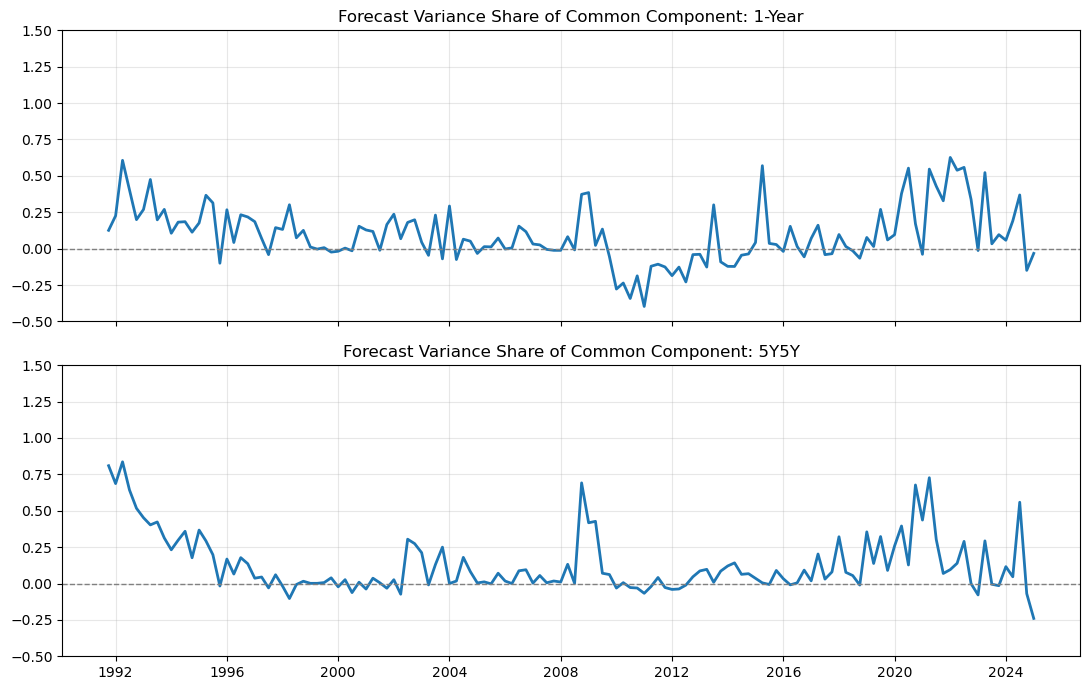

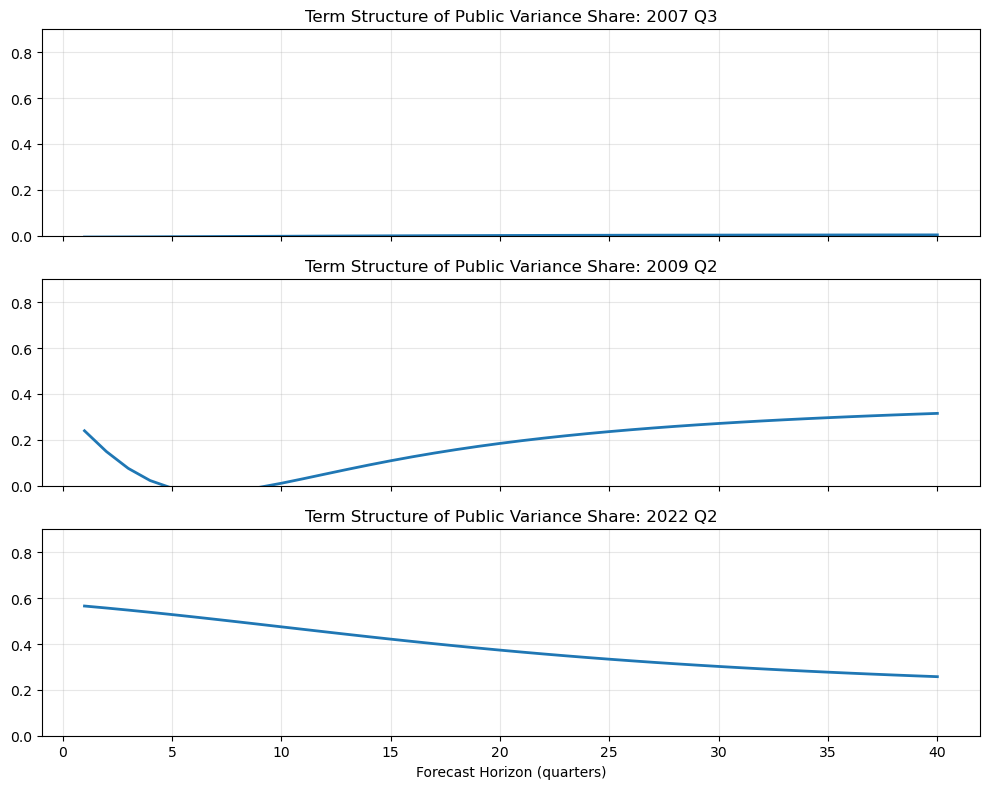

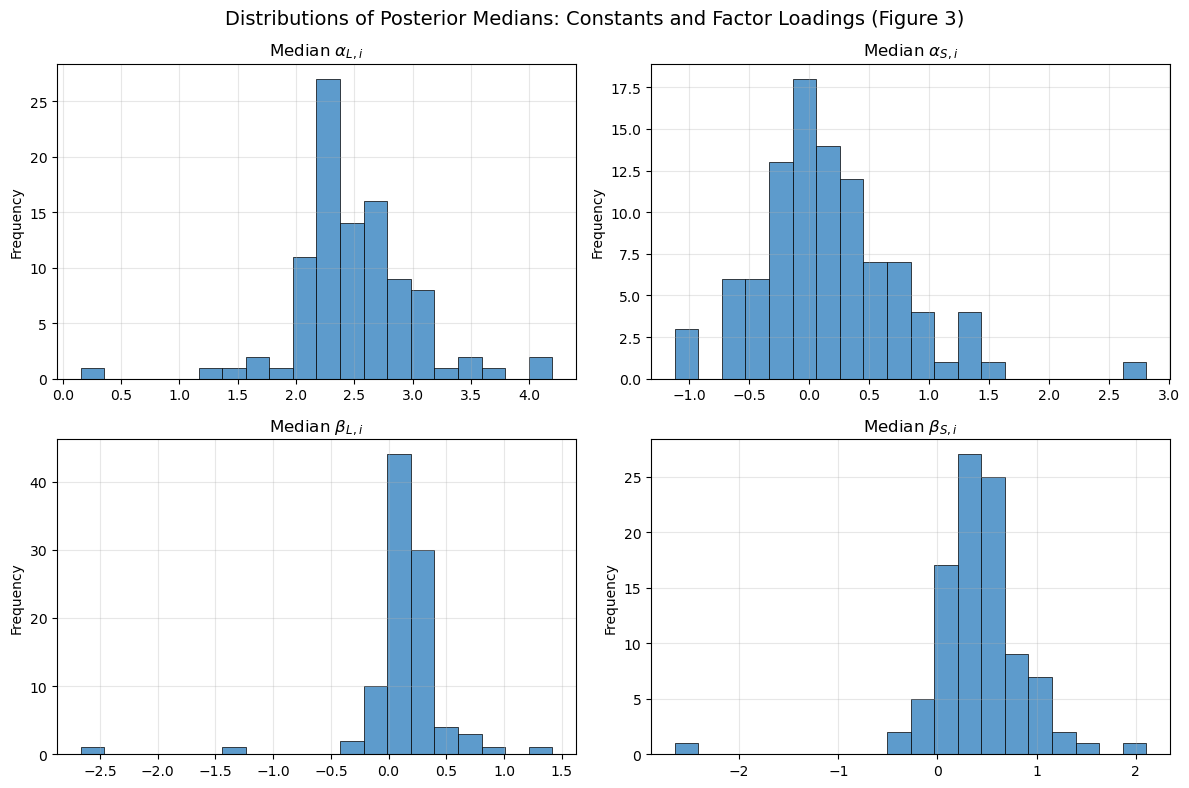

[1] Shocks Loaded: 431 months
[2] Macro Loaded: 682 months
[3] Decomposition: 134 quarters
[4] Final merged sample: 336 months
[5] Local projections estimated.


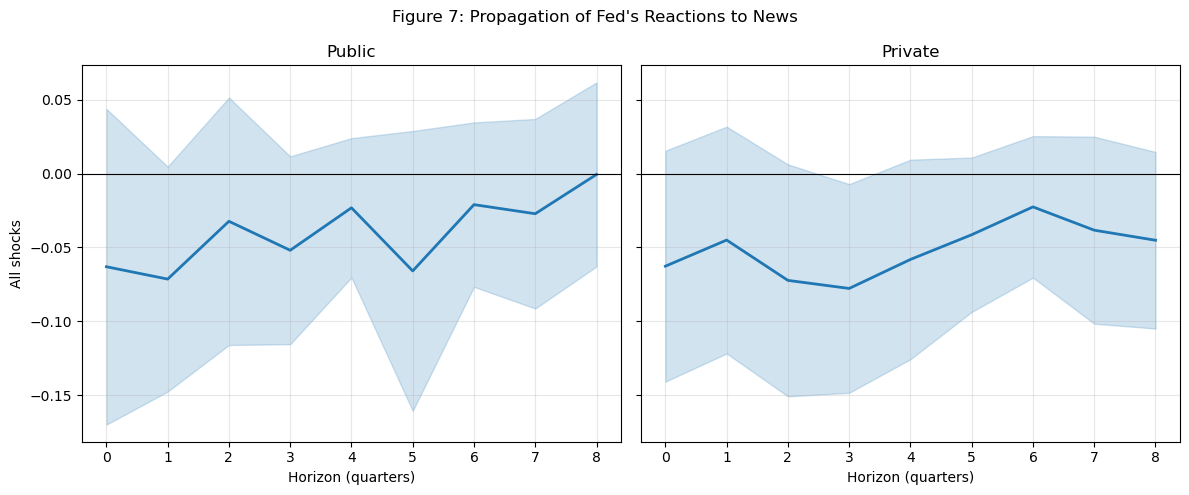

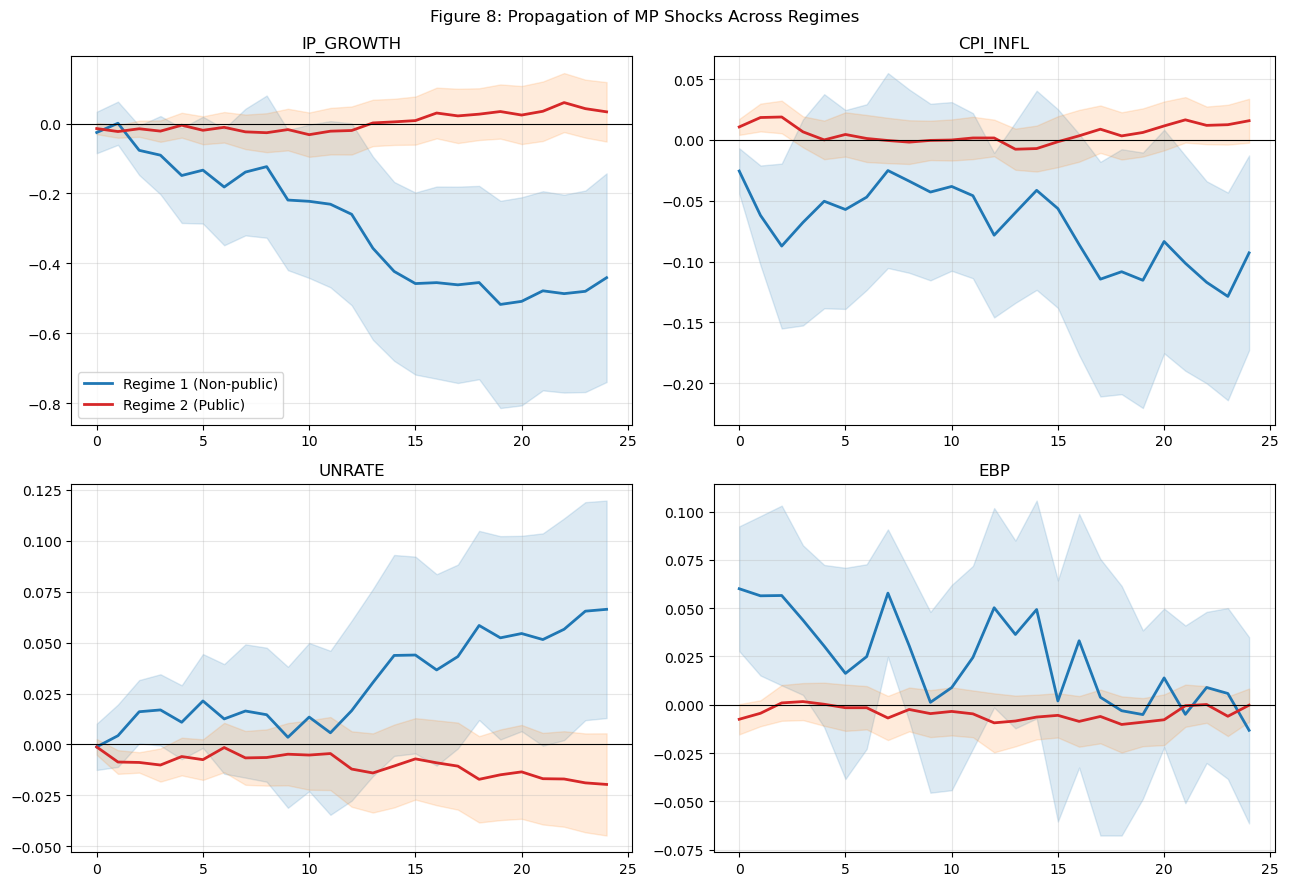


CELL 3 COMPLETED
No files saved.


In [ ]:

# ============================================================
# CELL 3 — AHN–FARMER REPLICATION
# VARIANCE DECOMPOSITION / FIGURES 3–8 / LP
# Requires outputs from Cell 2
# Nothing saved
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from pathlib import Path

# ============================================================
# 1. FUJITA-RAMEY VARIANCE DECOMPOSITION
# ============================================================

def compute_shares(h_val):
    ah = (
        1.0-np.exp(-lam*h_val)
    )/(lam*h_val)

    t_ltb, t_pub, t_priv = [], [], []

    for t in range(T):
        resp = np.flatnonzero(active[t])

        if len(resp) < 10:
            t_ltb.append(np.nan)
            t_pub.append(np.nan)
            t_priv.append(np.nan)
            continue

        pi_ltb = (
            theta[resp, 0]
            - ah*theta[resp, 1]
        )

        pi_pub = (
            theta[resp, 2]*C[t, 0]
            - ah*theta[resp, 3]*C[t, 1]
        )

        pi_priv = (
            E[t, resp, 0]
            - ah*E[t, resp, 1]
        )

        pi_total = pi_ltb + pi_pub + pi_priv

        var_tot = np.var(pi_total, ddof=1)

        if var_tot < 1e-10:
            t_ltb.append(np.nan)
            t_pub.append(np.nan)
            t_priv.append(np.nan)
            continue

        cov_mat = np.cov(
            np.vstack([
                pi_total,
                pi_ltb,
                pi_pub,
                pi_priv
            ])
        )

        t_ltb.append(cov_mat[0, 1]/var_tot)
        t_pub.append(cov_mat[0, 2]/var_tot)
        t_priv.append(cov_mat[0, 3]/var_tot)

    return (
        np.array(t_ltb),
        np.array(t_pub),
        np.array(t_priv)
    )


def compute_forward_5y5y_shares():

    a20 = (
        1.0-np.exp(-lam*20.0)
    )/(lam*20.0)

    a40 = (
        1.0-np.exp(-lam*40.0)
    )/(lam*40.0)

    t_ltb, t_pub, t_priv = [], [], []

    for t in range(T):
        resp = np.flatnonzero(active[t])

        if len(resp) < 10:
            t_ltb.append(np.nan)
            t_pub.append(np.nan)
            t_priv.append(np.nan)
            continue

        ltb_20 = (
            theta[resp, 0]
            - a20*theta[resp, 1]
        )

        pub_20 = (
            theta[resp, 2]*C[t, 0]
            - a20*theta[resp, 3]*C[t, 1]
        )

        priv_20 = (
            E[t, resp, 0]
            - a20*E[t, resp, 1]
        )

        ltb_40 = (
            theta[resp, 0]
            - a40*theta[resp, 1]
        )

        pub_40 = (
            theta[resp, 2]*C[t, 0]
            - a40*theta[resp, 3]*C[t, 1]
        )

        priv_40 = (
            E[t, resp, 0]
            - a40*E[t, resp, 1]
        )

        pi_ltb = 2.0*ltb_40 - ltb_20
        pi_pub = 2.0*pub_40 - pub_20
        pi_priv = 2.0*priv_40 - priv_20

        pi_total = pi_ltb + pi_pub + pi_priv

        var_tot = np.var(pi_total, ddof=1)

        if var_tot < 1e-10:
            t_ltb.append(np.nan)
            t_pub.append(np.nan)
            t_priv.append(np.nan)
            continue

        cov_mat = np.cov(
            np.vstack([
                pi_total,
                pi_ltb,
                pi_pub,
                pi_priv
            ])
        )

        t_ltb.append(cov_mat[0, 1]/var_tot)
        t_pub.append(cov_mat[0, 2]/var_tot)
        t_priv.append(cov_mat[0, 3]/var_tot)

    return (
        np.array(t_ltb),
        np.array(t_pub),
        np.array(t_priv)
    )

# ============================================================
# 2. COMPUTE VARIANCE SHARES
# ============================================================

ltb_1y, pub_1y, priv_1y = compute_shares(4.0)

ltb_5y5y, pub_5y5y, priv_5y5y = (
    compute_forward_5y5y_shares()
)

decomp_df = pd.DataFrame({
    "date": dates,
    "pub_1y": pub_1y,
    "pub_5y5y": pub_5y5y
}).set_index("date")

print("\nVARIANCE DECOMPOSITION")

print(
    "1Y identity error:",
    np.nanmax(np.abs(
        ltb_1y + pub_1y + priv_1y - 1
    ))
)

print(
    "5Y5Y identity error:",
    np.nanmax(np.abs(
        ltb_5y5y + pub_5y5y + priv_5y5y - 1
    ))
)

# ============================================================
# 3. FIGURE 5
# ============================================================

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(11, 7), sharex=True
)

ax1.plot(
    decomp_df.index,
    decomp_df["pub_1y"],
    color="tab:blue",
    lw=2
)

ax1.axhline(
    0, color="gray", linestyle="--", lw=1
)

ax1.set_title(
    "Forecast Variance Share of Common Component: 1-Year"
)
ax1.set_ylim(-0.5, 1.5)
ax1.grid(alpha=0.3)

ax2.plot(
    decomp_df.index,
    decomp_df["pub_5y5y"],
    color="tab:blue",
    lw=2
)

ax2.axhline(
    0, color="gray", linestyle="--", lw=1
)

ax2.set_title(
    "Forecast Variance Share of Common Component: 5Y5Y"
)
ax2.set_ylim(-0.5, 1.5)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ============================================================
# 4. FIGURE 6 — TERM STRUCTURE
# ============================================================

horizons = np.arange(1, 41)

target_dates = [
    "2007-07-01",
    "2009-04-01",
    "2022-04-01"
]

fig, axes = plt.subplots(
    3, 1, figsize=(10, 8), sharex=True
)

for ax, t_label in zip(axes, target_dates):

    t_dt = pd.to_datetime(t_label)

    t_idx = np.argmin(
        np.abs(dates-t_dt)
    )

    shares_curve = []

    for h in horizons:
        _, pub_h, _ = compute_shares(float(h))
        shares_curve.append(pub_h[t_idx])

    ax.plot(
        horizons,
        shares_curve,
        color="tab:blue",
        lw=2
    )

    ax.set_title(
        "Term Structure of Public Variance Share: "
        f"{dates[t_idx].year} Q{dates[t_idx].quarter}"
    )

    ax.set_ylim(0, 0.9)
    ax.grid(alpha=0.3)

axes[-1].set_xlabel(
    "Forecast Horizon (quarters)"
)

plt.tight_layout()
plt.show()

# ============================================================
# 5. FIGURE 3 — INDIVIDUAL COEFFICIENT DISTRIBUTIONS
# ============================================================

fig, axes = plt.subplots(
    2, 2, figsize=(12, 8)
)

fig3_variables = [
    (0, r"Median $\alpha_{L,i}$"),
    (1, r"Median $\alpha_{S,i}$"),
    (2, r"Median $\beta_{L,i}$"),
    (3, r"Median $\beta_{S,i}$")
]

for ax, (j, title) in zip(
    axes.flat, fig3_variables
):
    ax.hist(
        theta[:, j],
        bins=20,
        color="#5D9BCC",
        edgecolor="black",
        linewidth=0.5
    )

    ax.set_title(title, fontsize=12)
    ax.grid(alpha=0.3)
    ax.set_ylabel("Frequency", fontsize=10)

plt.suptitle(
    "Distributions of Posterior Medians: "
    "Constants and Factor Loadings (Figure 3)",
    fontsize=14,
    y=0.98
)

plt.tight_layout()
plt.show()

# ============================================================
# 6. LOAD BAUER-SWANSON SHOCKS
# ============================================================

ROOT = Path(r"C:\Users\gayeon\Dropbox\key_data")

SHOCK_FILE = (
    ROOT / "monetary-policy-surprises-data.xlsx"
)

MACRO_FILE = (
    ROOT / "macro" / "processed"
    / "macro_monthly.csv"
)

# Use the Excel metadata workaround from Cell 1
def read_excel_safe(path, sheet_name):
    buffer = BytesIO()

    with ZipFile(path, "r") as src:
        with ZipFile(
            buffer, "w", ZIP_DEFLATED
        ) as dst:

            for item in src.infolist():
                if item.filename == "docProps/core.xml":
                    continue

                dst.writestr(
                    item,
                    src.read(item.filename)
                )

    buffer.seek(0)

    return pd.read_excel(
        buffer,
        sheet_name=sheet_name,
        engine="openpyxl"
    )

shocks = read_excel_safe(
    SHOCK_FILE,
    sheet_name="FOMC (update 2023)"
)

shocks["date"] = pd.to_datetime(
    shocks["Date"]
)

shocks = (
    shocks.set_index("date")
    .resample("ME")
    .sum(numeric_only=True)
)

# Original shock definitions
shocks["news_raw"] = (
    shocks["MPS"] - shocks["MPS_ORTH"]
)

shocks["mp_raw"] = shocks["MPS_ORTH"]

shocks["news_shock"] = (
    shocks["news_raw"]
    - shocks["news_raw"].mean()
) / shocks["news_raw"].std()

shocks["mp_shock"] = (
    shocks["mp_raw"]
    - shocks["mp_raw"].mean()
) / shocks["mp_raw"].std()

print(
    "[1] Shocks Loaded:",
    len(shocks), "months"
)

# ============================================================
# 7. LOAD MACRO DATA
# ============================================================

macro_m = pd.read_csv(
    MACRO_FILE,
    parse_dates=["date"]
)

macro_m = (
    macro_m.set_index("date")
    .resample("ME")
    .last()
    .copy()
)

print(
    "[2] Macro Loaded:",
    len(macro_m), "months"
)

# Original private shares
decomp_df["priv_1y"] = priv_1y
decomp_df["priv_5y5y"] = priv_5y5y

print(
    "[3] Decomposition:",
    len(decomp_df), "quarters"
)

# ============================================================
# 8. MERGE MONTHLY DATA
# ============================================================

df_m = macro_m.join(
    shocks[["news_shock", "mp_shock"]],
    how="inner"
)

df_m = df_m.join(
    decomp_df.resample("ME").ffill(),
    how="left"
)

df_m["theta_pub_5y5y"] = (
    df_m.get("pub_5y5y", 0.1)
)

df_m["theta_priv_1y"] = (
    df_m.get("priv_1y", 0.1)
)

df_m["regime_s"] = (
    df_m["theta_pub_5y5y"]
    .shift(3)
    .clip(lower=0.0, upper=1.0)
)

if "INDPRO" in df_m.columns:
    df_m["ip_growth"] = (
        100.0*np.log(df_m["INDPRO"]).diff()
    )

if "CPIAUCSL" in df_m.columns:
    df_m["cpi_infl"] = (
        100.0*np.log(df_m["CPIAUCSL"]).diff()
    )

potential_controls = [
    "ip_growth",
    "cpi_infl",
    "UNRATE",
    "ebp"
]

actual_controls = [
    c for c in potential_controls
    if c in df_m.columns
]

control_cols = []

for c in actual_controls:
    for lag in range(1, 13):

        col_name = f"{c}_lag{lag}"

        df_m[col_name] = (
            df_m[c].shift(lag)
        )

        control_cols.append(col_name)

req_cols = (
    control_cols
    + ["news_shock", "mp_shock", "regime_s"]
)

df_clean = (
    df_m.dropna(subset=req_cols)
    .loc["1992-01-31":"2019-12-31"]
    .copy()
)

print(
    "[4] Final merged sample:",
    len(df_clean), "months"
)

if len(df_clean) == 0:
    raise ValueError(
        "Merged sample has zero observations."
    )

# ============================================================
# 9. FIGURE 7 — LINEAR LOCAL PROJECTION
# ============================================================

df_q = df_clean.resample("QE").mean()

H_FIG7 = 8

res_fig7 = {
    "pub": {"irf": [], "se": []},
    "priv": {"irf": [], "se": []}
}

target_disagreement = {
    "pub": "theta_pub_5y5y",
    "priv": "theta_priv_1y"
}

for key, var in target_disagreement.items():

    if var not in df_q.columns:
        continue

    for h in range(H_FIG7+1):

        y_lead = df_q[var].shift(-h)

        valid = (
            y_lead.notna()
            & df_q["news_shock"].notna()
        )

        valid_idx = df_q.index[valid]

        if len(valid_idx) < 10:
            res_fig7[key]["irf"].append(np.nan)
            res_fig7[key]["se"].append(np.nan)
            continue

        y_curr = y_lead.loc[valid_idx]

        X = sm.add_constant(
            df_q.loc[
                valid_idx, "news_shock"
            ]
        )

        model = sm.OLS(
            y_curr, X
        ).fit(
            cov_type="HAC",
            cov_kwds={"maxlags": h+1}
        )

        res_fig7[key]["irf"].append(
            model.params["news_shock"]
        )

        res_fig7[key]["se"].append(
            model.bse["news_shock"]
        )

# ============================================================
# 10. FIGURE 8 — NONLINEAR LOCAL PROJECTION
# ============================================================

H_FIG8 = 24

res_fig8 = {
    v: {
        "irf1": [],
        "se1": [],
        "irf2": [],
        "se2": []
    }
    for v in actual_controls
}

for v in res_fig8.keys():

    for h in range(H_FIG8+1):

        if v in ["ip_growth", "cpi_infl"]:
            y_lead = (
                df_clean[v]
                .rolling(window=h+1)
                .sum()
                .shift(-h)
            )
        else:
            y_lead = df_clean[v].shift(-h)

        valid = (
            y_lead.notna()
            & df_clean["mp_shock"].notna()
            & df_clean["regime_s"].notna()
        )

        valid_idx = df_clean.index[valid]

        if len(valid_idx) < 10:
            res_fig8[v]["irf1"].append(np.nan)
            res_fig8[v]["se1"].append(np.nan)
            res_fig8[v]["irf2"].append(np.nan)
            res_fig8[v]["se2"].append(np.nan)
            continue

        y_curr = y_lead.loc[valid_idx]

        s_lag = df_clean.loc[
            valid_idx, "regime_s"
        ]

        z_t = df_clean.loc[
            valid_idx, "mp_shock"
        ]

        X = pd.DataFrame({
            "const": 1.0,
            "shock_r1": (1.0-s_lag)*z_t,
            "shock_r2": s_lag*z_t
        }, index=valid_idx)

        X = X.join(
            df_clean.loc[
                valid_idx, control_cols
            ]
        )

        model = sm.OLS(
            y_curr, X
        ).fit(
            cov_type="HAC",
            cov_kwds={"maxlags": h+1}
        )

        res_fig8[v]["irf1"].append(
            model.params["shock_r1"]*0.9
        )

        res_fig8[v]["se1"].append(
            model.bse["shock_r1"]*0.9
        )

        res_fig8[v]["irf2"].append(
            model.params["shock_r2"]*0.1
        )

        res_fig8[v]["se2"].append(
            model.bse["shock_r2"]*0.1
        )

print("[5] Local projections estimated.")

# ============================================================
# 11. FIGURE 7 PLOT
# ============================================================

z_crit_95 = 1.96
z_crit_90 = 1.645

fig7, axes7 = plt.subplots(
    1, 2, figsize=(12, 5), sharey=True
)

h_axis7 = np.arange(H_FIG7+1)

for i, (key, title) in enumerate([
    ("pub", "Public"),
    ("priv", "Private")
]):

    if not res_fig7[key]["irf"]:
        continue

    irf = np.array(
        res_fig7[key]["irf"], dtype=float
    )

    se = np.array(
        res_fig7[key]["se"], dtype=float
    )

    mask = ~np.isnan(irf)

    axes7[i].plot(
        h_axis7[mask],
        irf[mask],
        color="tab:blue",
        lw=2
    )

    axes7[i].fill_between(
        h_axis7[mask],
        irf[mask]-z_crit_95*se[mask],
        irf[mask]+z_crit_95*se[mask],
        color="tab:blue",
        alpha=0.2
    )

    axes7[i].axhline(
        0, color="black", lw=0.8
    )

    axes7[i].set_title(title)
    axes7[i].grid(alpha=0.3)
    axes7[i].set_xlabel("Horizon (quarters)")

axes7[0].set_ylabel("All shocks")

fig7.suptitle(
    "Figure 7: Propagation of Fed's Reactions to News"
)

plt.tight_layout()
plt.show()

# ============================================================
# 12. FIGURE 8 PLOT
# ============================================================

fig8, axes8 = plt.subplots(
    2, 2, figsize=(13, 9)
)

h_axis8 = np.arange(H_FIG8+1)

for ax, v in zip(
    axes8.flat, actual_controls
):

    irf1 = np.array(
        res_fig8[v]["irf1"], dtype=float
    )

    se1 = np.array(
        res_fig8[v]["se1"], dtype=float
    )

    irf2 = np.array(
        res_fig8[v]["irf2"], dtype=float
    )

    se2 = np.array(
        res_fig8[v]["se2"], dtype=float
    )

    mask = ~np.isnan(irf1)

    ax.plot(
        h_axis8[mask],
        irf1[mask],
        color="tab:blue",
        lw=2,
        label="Regime 1 (Non-public)"
    )

    ax.fill_between(
        h_axis8[mask],
        irf1[mask]-z_crit_90*se1[mask],
        irf1[mask]+z_crit_90*se1[mask],
        color="tab:blue",
        alpha=0.15
    )

    ax.plot(
        h_axis8[mask],
        irf2[mask],
        color="tab:red",
        lw=2,
        label="Regime 2 (Public)"
    )

    ax.fill_between(
        h_axis8[mask],
        irf2[mask]-z_crit_90*se2[mask],
        irf2[mask]+z_crit_90*se2[mask],
        color="tab:orange",
        alpha=0.15
    )

    ax.axhline(
        0, color="black", lw=0.8
    )

    ax.set_title(v.upper())
    ax.grid(alpha=0.3)

    if v == "ip_growth":
        ax.legend()

fig8.suptitle(
    "Figure 8: Propagation of MP Shocks Across Regimes"
)

plt.tight_layout()
plt.show()

print("\nCELL 3 COMPLETED")
print("No files saved.")
